In [1]:
import sys
import os
import pickle
from typing import NamedTuple
import math
import numpy as np
import scipy as sp
import pandas as pd
from matplotlib import pyplot as plt


sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_worm import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/train_utils.py'>

In [3]:
ll = 'll00'
data_variants = [
	'gcamp',
	'gfp',
	'art',
]
model_variant = 'ss'
organism = 'worm-2025-fieseler'

In [4]:
if 'gcamp' in data_variants:
	# file_ids_gcamp = list(range(0, 33+1))
	file_ids_gcamp = [19]

	path_gcamp = os.path.join(read_utils.get_data_path(), 'exported_data_gcamp')
	filenames_gcamp = [read_utils.get_filename(read_utils.get_file_handle(path_gcamp, file_id)) for file_id in file_ids_gcamp]

if 'gfp' in data_variants:
	# file_ids_gfp = list(range(0, 7+1))
	file_ids_gfp = [2]

	path_gfp = os.path.join(read_utils.get_data_path(), 'exported_data_gfp')
	filenames_gfp = [read_utils.get_filename(read_utils.get_file_handle(path_gfp, file_id)) for file_id in file_ids_gfp]

if 'art' in data_variants and 'gfp' in data_variants:
	file_ids_art = file_ids_gfp.copy()

	filenames_art = [filename.replace('worm', 'wyrm') for filename in filenames_gfp]

In [5]:
manual_reg_lambdas = {
	'wb_reg_lambda': 1E-1,
	'wm_reg_lambda': 1E-9,
}

with open('../../src/hyperparams.pkl', 'rb') as file:
    swept_params = pickle.load(file)
swept_reg_lambdas = dict()
for model in swept_params[ll].keys():
	type_, variant = model.split('_')
	if variant not in swept_reg_lambdas.keys():
		swept_reg_lambdas[variant] = dict()
	if type_ not in swept_reg_lambdas[variant].keys():
		swept_reg_lambdas[variant][type_] = dict()
	for param in swept_params[ll][model]['means'].keys():
		swept_reg_lambdas[variant][type_][param] = swept_params[ll][model]['means'][param]['geometric']


reg_lambdas = swept_reg_lambdas.copy()

if 'gcamp' in data_variants:
	bom_folder_gcamp = (f'{'gcamp'}_bom_{model_variant}_'
				  + '_'.join([f'{param.split('_')[0]}{reg_lambdas[model_variant]['bom'][param]:.2E}' for param in reg_lambdas[model_variant]['bom'].keys()]))
	hgm_folder_gcamp = (f'{'gcamp'}_hgm_{model_variant}_'
				  + '_'.join([f'{param.split('_')[0]}{reg_lambdas[model_variant]['hgm'][param]:.2E}' for param in reg_lambdas[model_variant]['hgm'].keys()]))

if 'gfp' in data_variants:
	bom_folder_gfp = (f'{'gfp'}_bom_{model_variant}_'
				  + '_'.join([f'{param.split('_')[0]}{reg_lambdas[model_variant]['bom'][param]:.2E}' for param in reg_lambdas[model_variant]['bom'].keys()]))
	hgm_folder_gfp = (f'{'gfp'}_hgm_{model_variant}_'
				  + '_'.join([f'{param.split('_')[0]}{reg_lambdas[model_variant]['hgm'][param]:.2E}' for param in reg_lambdas[model_variant]['hgm'].keys()]))

if 'art' in data_variants:
	bom_folder_art = (f'{'art'}_bom_{model_variant}_'
				  + '_'.join([f'{param.split('_')[0]}{reg_lambdas[model_variant]['bom'][param]:.2E}' for param in reg_lambdas[model_variant]['bom'].keys()]))
	hgm_folder_art = (f'{'art'}_hgm_{model_variant}_'
				  + '_'.join([f'{param.split('_')[0]}{reg_lambdas[model_variant]['hgm'][param]:.2E}' for param in reg_lambdas[model_variant]['hgm'].keys()]))

In [6]:
def assemble(boms_scores_per_neuron, hgms_scores_per_neuron):
	neurons_labels = [scores_per_neuron[0].columns for scores_per_neuron in hgms_scores_per_neuron]

	boms_scores_per_neuron = [np.array([split.values[0] for split in scores]) for scores in boms_scores_per_neuron]
	hgms_scores_per_neuron = [np.array([split.values[0] for split in scores]) for scores in hgms_scores_per_neuron]

	neuron_scores = dict()
	boms_scores_per_neuron_avg = [np.mean(scores, axis=0) for scores in boms_scores_per_neuron]
	hgms_scores_per_neuron_avg = [np.mean(scores, axis=0) for scores in hgms_scores_per_neuron]
	for label_list, score_bom_list, score_hgm_list in zip(neurons_labels, boms_scores_per_neuron_avg, hgms_scores_per_neuron_avg):
		sort_indices = np.argsort(score_hgm_list)[::-1]
		label_list = label_list[sort_indices]
		score_bom_list = score_bom_list[sort_indices]
		score_hgm_list = score_hgm_list[sort_indices]

		for i in range(len(label_list)):
			label = label_list[i]
			if label != '' and label[-1] != '_':
				score_bom_new, score_hgm_new = np.array(score_bom_list[i]), np.array(score_hgm_list[i])
				if len(score_hgm_new.shape) == 0:
					score_bom_new = score_bom_new.reshape(1, 1)
					score_hgm_new = score_hgm_new.reshape(1, 1)
				if label not in neuron_scores.keys():
					neuron_scores[label] = (score_bom_new, score_hgm_new)
				else:
					score_bom_prev, score_hgm_prev = neuron_scores[label]
					neuron_scores[label] = (np.vstack([score_bom_prev, score_bom_new]), np.vstack([score_hgm_prev, score_hgm_new]))

	return neuron_scores

In [7]:
if 'gcamp' in data_variants:
	boms_spn_gcamp = [train_utils.load_predictions(os.path.join(read_utils.get_model_path(), 'predictions', bom_folder_gcamp), filename)[0] for filename in filenames_gcamp]
	hgms_spn_gcamp = [train_utils.load_predictions(os.path.join(read_utils.get_model_path(), 'predictions', hgm_folder_gcamp), filename)[0] for filename in filenames_gcamp]

if 'gfp' in data_variants:
	boms_spn_gfp = [train_utils.load_predictions(os.path.join(read_utils.get_model_path(), 'predictions', bom_folder_gfp), filename)[0] for filename in filenames_gfp]
	hgms_spn_gfp = [train_utils.load_predictions(os.path.join(read_utils.get_model_path(), 'predictions', hgm_folder_gfp), filename)[0] for filename in filenames_gfp]

if 'art' in data_variants:
	boms_spn_art = [train_utils.load_predictions(os.path.join(read_utils.get_model_path(), 'predictions', bom_folder_art), filename)[0] for filename in filenames_art]
	hgms_spn_art = [train_utils.load_predictions(os.path.join(read_utils.get_model_path(), 'predictions', hgm_folder_art), filename)[0] for filename in filenames_art]

In [8]:
if 'gcamp' in data_variants:
	neuron_scores_gcamp = assemble(boms_spn_gcamp, hgms_spn_gcamp)

if 'gfp' in data_variants:
	neuron_scores_gfp = assemble(boms_spn_gfp, hgms_spn_gfp)

if 'art' in data_variants:
	neuron_scores_art = assemble(boms_spn_art, hgms_spn_art)

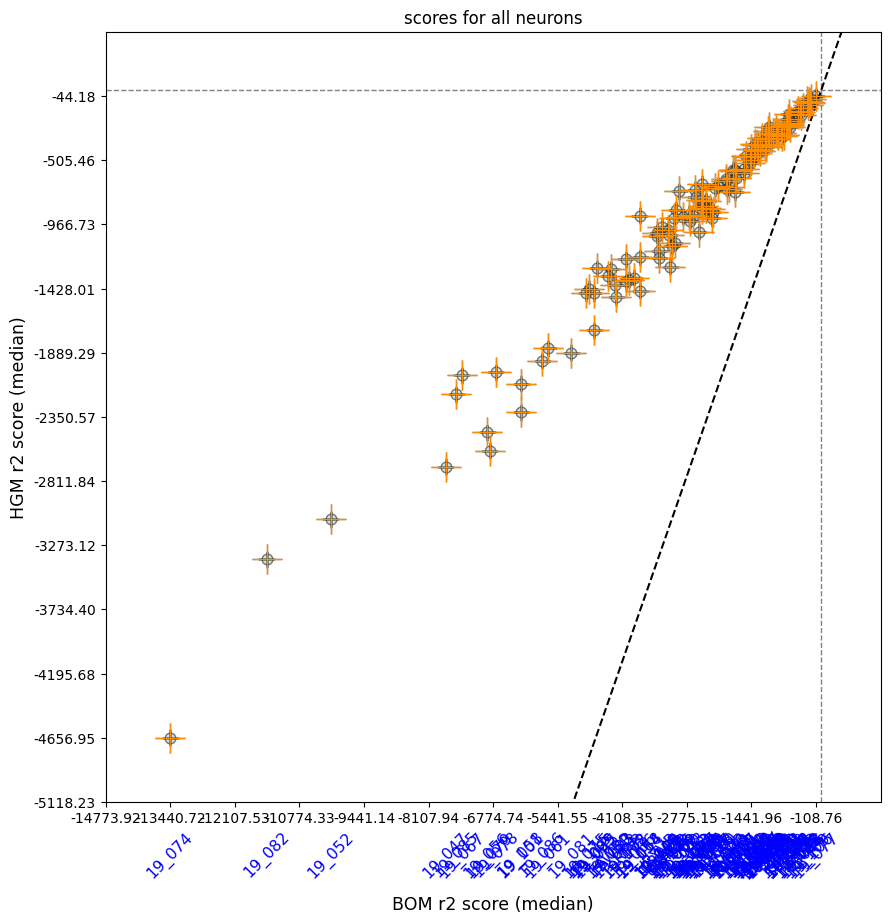

In [9]:
if 'gcamp' in data_variants:
	plot_utils.plot_performance_plot(
		neuron_scores_gcamp, None,
		title='scores for all neurons', limits=None, force_medians=True
	)

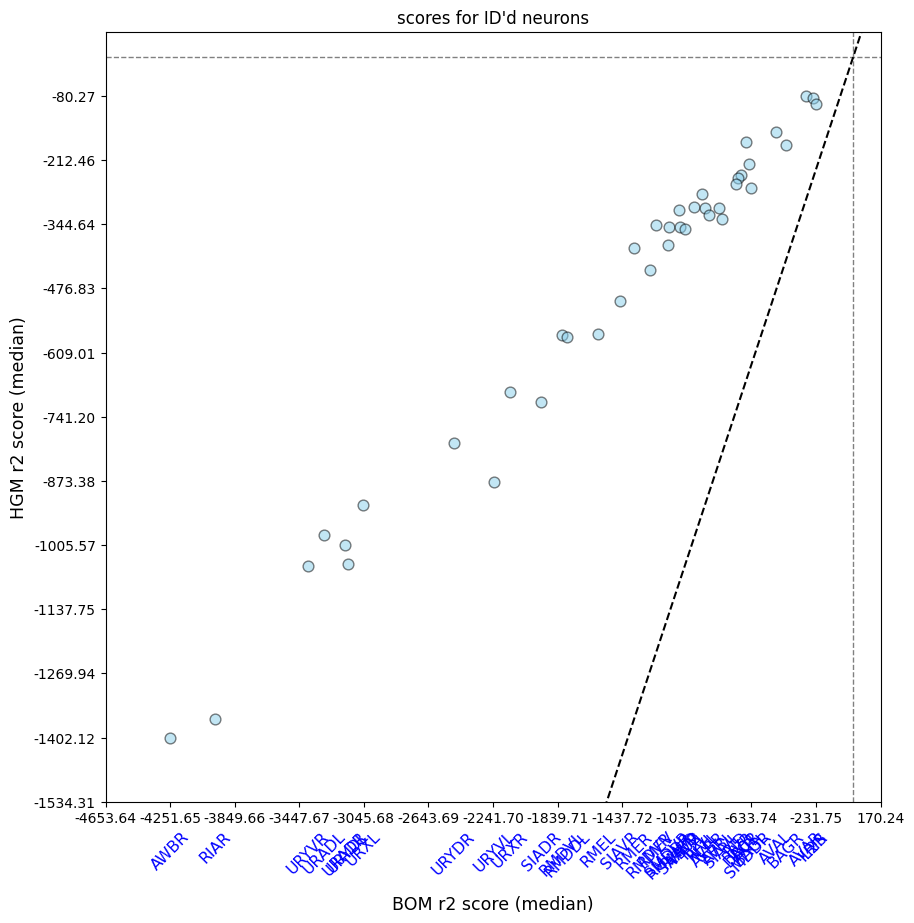

In [10]:
if 'gcamp' in data_variants:
	plot_utils.plot_performance_plot(
		{key: neuron_scores_gcamp[key] for key in neuron_scores_gcamp.keys() if not key[0].isdigit()}, None,
		title='scores for ID\'d neurons', limits=None
	)

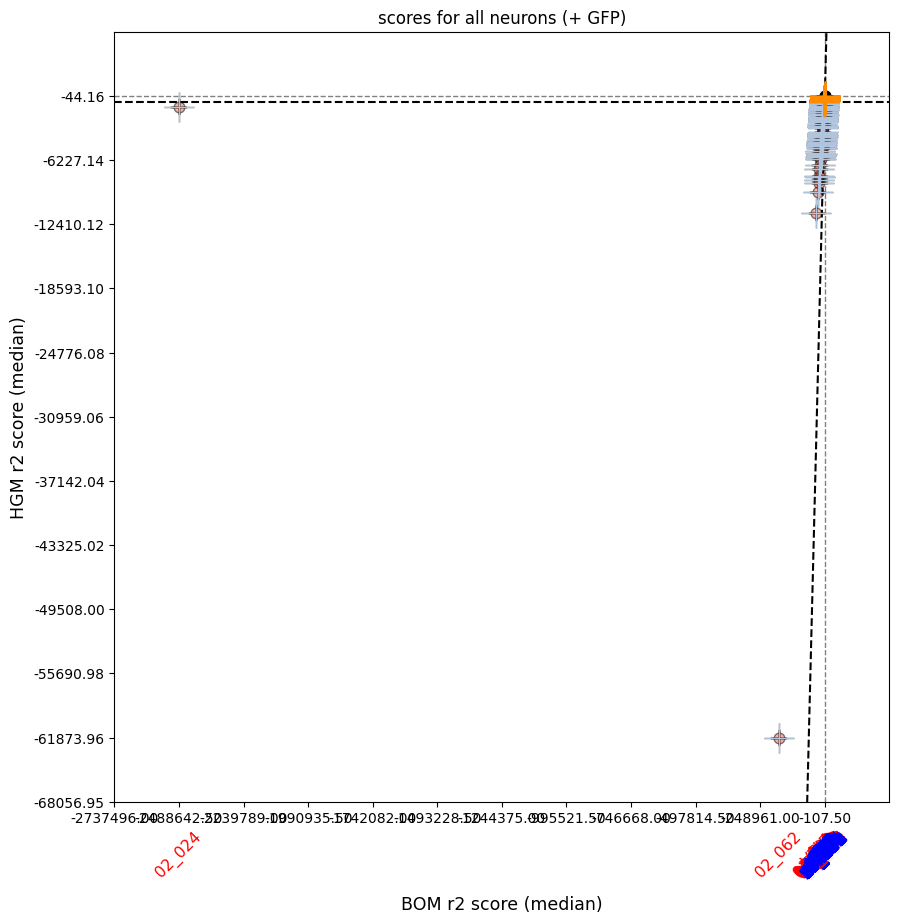

In [11]:
if 'gcamp' in data_variants and 'gfp' in data_variants:
	plot_utils.plot_performance_plot(
		neuron_scores_gcamp, neuron_scores_gfp,
		title='scores for all neurons (+ GFP)', limits=None, force_medians=True
	)

In [12]:
if 'gcamp' in data_variants and 'gfp' in data_variants:
	threshold_hgm_gfp = np.quantile(np.concatenate([pair[1] for pair in neuron_scores_gfp.values()]), 0.95)

	significant_hgm_n_gcamp = list()
	for key in neuron_scores_gcamp.keys():
		scores_bom, scores_hgm = neuron_scores_gcamp[key]
		if len(scores_hgm.shape) == 0:
			scores_bom = scores_bom.reshape(1, 1)
			scores_hgm = scores_hgm.reshape(1, 1)
		y = np.median(scores_hgm)
		if y > threshold_hgm_gfp:
			significant_hgm_n_gcamp.append(key)

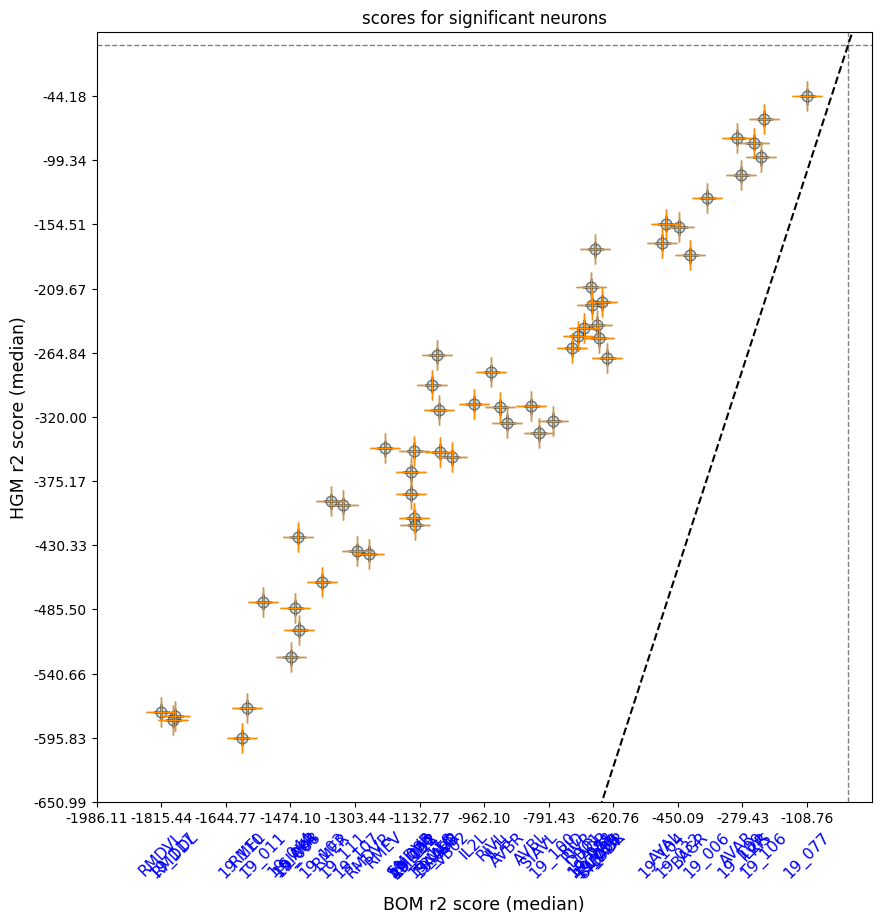

In [13]:
if 'gcamp' in data_variants and 'gfp' in data_variants:
	plot_utils.plot_performance_plot(
		{key: neuron_scores_gcamp[key] for key in significant_hgm_n_gcamp}, None,
		title='scores for significant neurons', limits=None, force_medians=True
	)

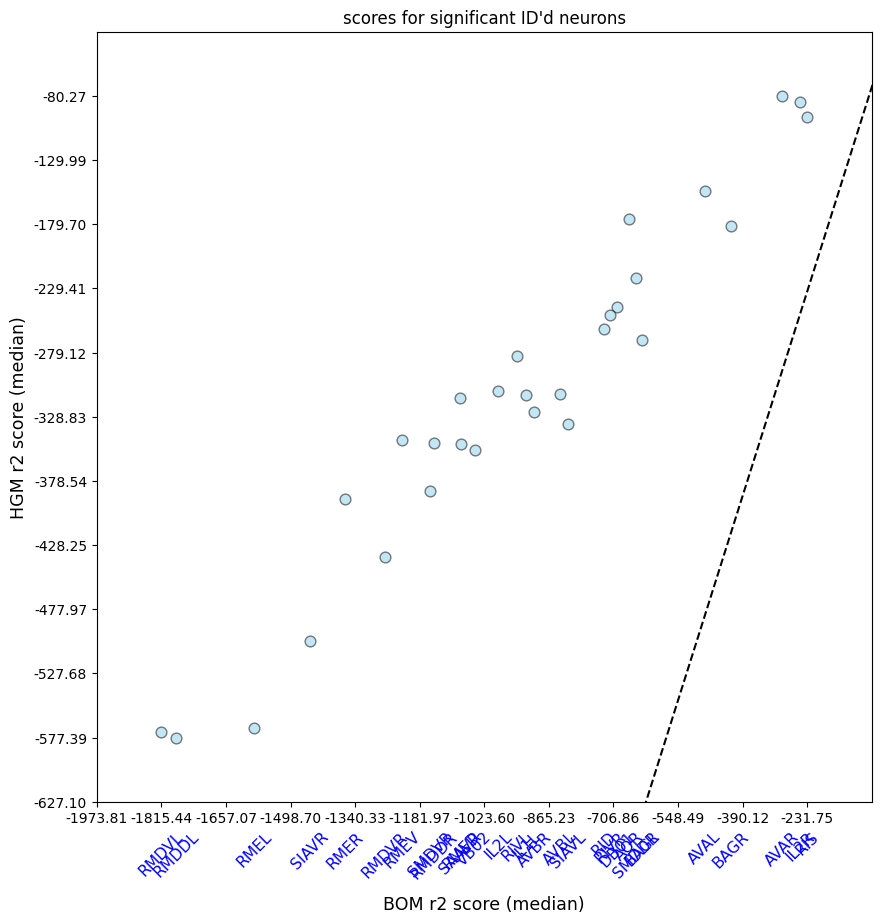

In [14]:
if 'gcamp' in data_variants and 'gfp' in data_variants:
	plot_utils.plot_performance_plot(
		{key: neuron_scores_gcamp[key] for key in significant_hgm_n_gcamp if not key[0].isdigit()}, None,
		title='scores for significant ID\'d neurons', limits=None
	)

In [15]:
if 'gcamp' in data_variants and 'gfp' in data_variants:
	print('\n'.join([f'NEURON: {key},\tHGM: {np.median(val[1]):.4f}\tBOM: {np.median(val[0]):.4f}' for key, val in reversed(sorted(neuron_scores_gcamp.items(), key=lambda x: np.median(x[1][1]))) if key in significant_hgm_n_gcamp and not key[0].isdigit()]))

NEURON: AVAR,	HGM: -80.2741	BOM: -292.8884
NEURON: IL2R,	HGM: -84.5715	BOM: -249.2358
NEURON: RIS,	HGM: -96.6865	BOM: -231.7524
NEURON: AVAL,	HGM: -153.7952	BOM: -482.5295
NEURON: AQR,	HGM: -175.8585	BOM: -668.0988
NEURON: BAGR,	HGM: -180.9156	BOM: -417.7593
NEURON: SMDDR,	HGM: -221.3185	BOM: -650.3655
NEURON: DB01,	HGM: -243.4568	BOM: -697.5679
NEURON: RIVR,	HGM: -250.2255	BOM: -715.0127
NEURON: RID,	HGM: -261.0343	BOM: -729.5505
NEURON: BAGL,	HGM: -268.9953	BOM: -636.8141
NEURON: RIVL,	HGM: -281.6360	BOM: -943.5472
NEURON: IL2L,	HGM: -308.8166	BOM: -989.1712
NEURON: AVBL,	HGM: -310.8546	BOM: -838.2180
NEURON: IL1L,	HGM: -311.7943	BOM: -920.1895
NEURON: SAAVR,	HGM: -314.4558	BOM: -1082.0227
NEURON: AVBR,	HGM: -325.2188	BOM: -900.5070
NEURON: SIAVL,	HGM: -334.0699	BOM: -817.1825
NEURON: RMEV,	HGM: -346.8946	BOM: -1225.3118
NEURON: RMDDR,	HGM: -349.3590	BOM: -1146.5836
NEURON: RMED,	HGM: -349.9084	BOM: -1079.6667
NEURON: VB02,	HGM: -354.5879	BOM: -1047.4424
NEURON: SMDVR,	HGM: -386.1894

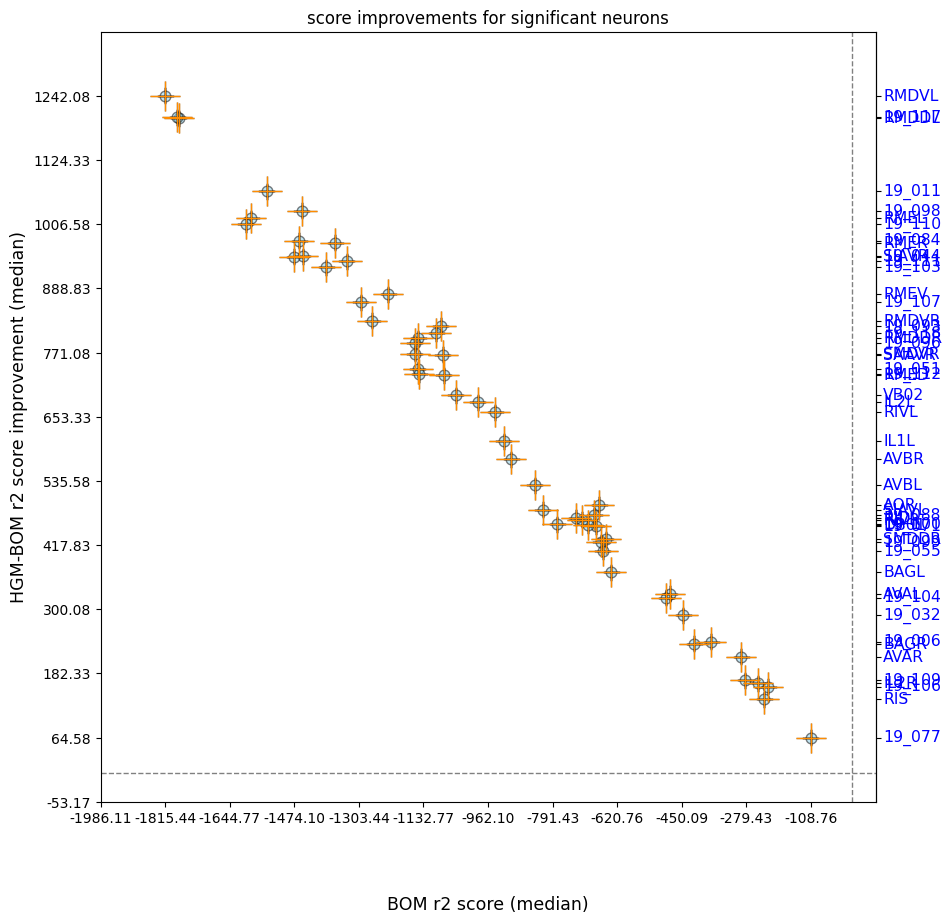

In [16]:
if 'gcamp' in data_variants and 'gfp' in data_variants:
	plot_utils.plot_improvement_plot(
		{key: neuron_scores_gcamp[key] for key in significant_hgm_n_gcamp},
		title='score improvements for significant neurons', limits=None, force_medians=True
	)

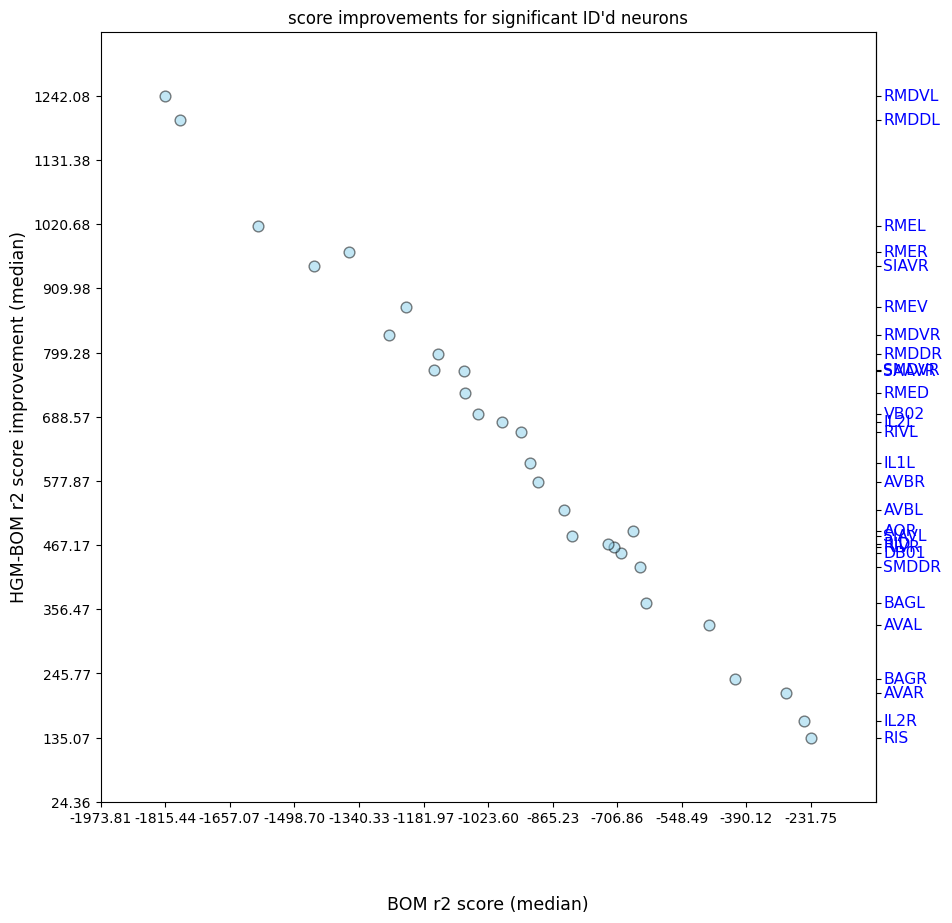

In [17]:
if 'gcamp' in data_variants and 'gfp' in data_variants:
	plot_utils.plot_improvement_plot(
		{key: neuron_scores_gcamp[key] for key in significant_hgm_n_gcamp if not key[0].isdigit()}, None,
		title='score improvements for significant ID\'d neurons', limits=None
	)

In [18]:
if 'gcamp' in data_variants and 'gfp' in data_variants:
	print('\n'.join([f'NEURON: {key},\tIMPR: {np.median(val[1] - val[0]):.4f}' for key, val in reversed(sorted(neuron_scores_gcamp.items(), key=lambda x: np.median(x[1][1] - x[1][0]))) if key in significant_hgm_n_gcamp and not key[0].isdigit()]))

NEURON: RMDVL,	IMPR: 1242.0818
NEURON: RMDDL,	IMPR: 1201.4944
NEURON: RMEL,	IMPR: 1018.1953
NEURON: RMER,	IMPR: 972.9265
NEURON: SIAVR,	IMPR: 948.1818
NEURON: RMEV,	IMPR: 878.4171
NEURON: RMDVR,	IMPR: 829.9532
NEURON: RMDDR,	IMPR: 797.2246
NEURON: SMDVR,	IMPR: 769.3525
NEURON: SAAVR,	IMPR: 767.5669
NEURON: RMED,	IMPR: 729.7584
NEURON: VB02,	IMPR: 692.8545
NEURON: IL2L,	IMPR: 680.3546
NEURON: RIVL,	IMPR: 661.9113
NEURON: IL1L,	IMPR: 608.3951
NEURON: AVBR,	IMPR: 575.2883
NEURON: AVBL,	IMPR: 527.3634
NEURON: AQR,	IMPR: 492.2403
NEURON: SIAVL,	IMPR: 483.1126
NEURON: RID,	IMPR: 468.5161
NEURON: RIVR,	IMPR: 464.7872
NEURON: DB01,	IMPR: 454.1111
NEURON: SMDDR,	IMPR: 429.0469
NEURON: BAGL,	IMPR: 367.8188
NEURON: AVAL,	IMPR: 328.7344
NEURON: BAGR,	IMPR: 236.8437
NEURON: AVAR,	IMPR: 212.6143
NEURON: IL2R,	IMPR: 164.6643
NEURON: RIS,	IMPR: 135.0659
